# 黑马头条项目｜第02天：APP端文章查看、FreeMarker静态化与MinIO

> 目标：完成 APP 文章列表的分页查询，掌握 FreeMarker 模板与原生静态化，再用 MinIO 存储图片和文章 HTML，最后串起文章详情静态页的生成链路。

本篇依据第02天讲义、配套图片和源码压缩包整理。源码只做静态参照，未启动服务、数据库、Docker、Nacos、MinIO 或 Nginx，也未调用任何接口。

## 学习地图与端到端链路

```text
APP/前端
   │  POST /api/v1/article/load*
   ▼
APP 网关 ──路由/跨域──▶ leadnews-article
                          │
             MyBatis-Plus 查询文章列表
                          │
        ap_article + ap_article_config + ap_article_content

发布/详情：文章内容 JSON → FreeMarker article.ftl → HTML → MinIO
                                             └→ ap_article.static_url
```

本日的核心分工是：MySQL 保存结构化文章元数据和内容，FreeMarker 负责把数据渲染成 HTML，MinIO 保存可直接读取的图片与静态页面；网关只负责统一入口和路由。

文章列表实现思路示意：

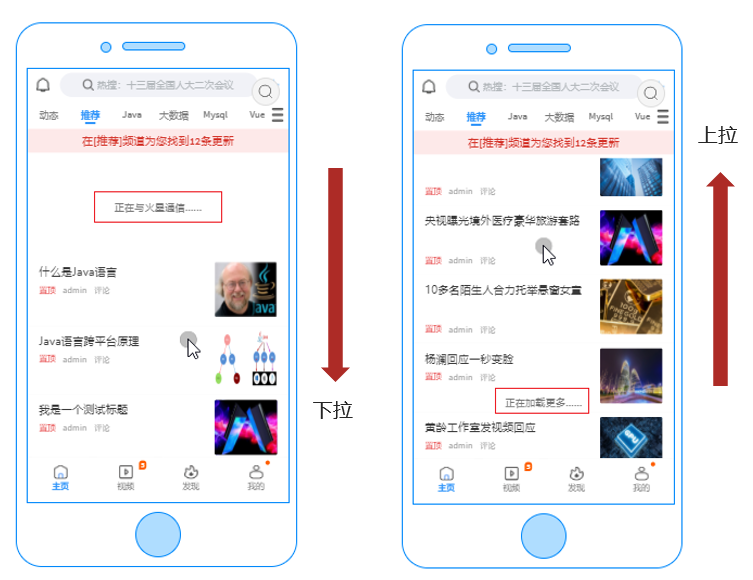

## 1. APP 端文章列表

### 1.1 需求与分页语义

首页展示默认频道的文章；用户切换频道后仍按发布时间倒序。下拉刷新取更新内容，上拉加载更多取更旧内容。分页游标使用当前列表的最大/最小 `publish_time`：

- `load`：首页，语义上等同于加载更多；
- `loadmore`：查询 `publish_time < minBehotTime`；
- `loadnew`：查询 `publish_time > maxBehotTime`；
- 首页默认可把 `maxBehotTime` 设为 `0`，把 `minBehotTime` 设为很大的未来毫秒值；
- 后端仍需兜底校验 `size`、时间和频道标签，单页上限示例为 50。

页面布局示意：

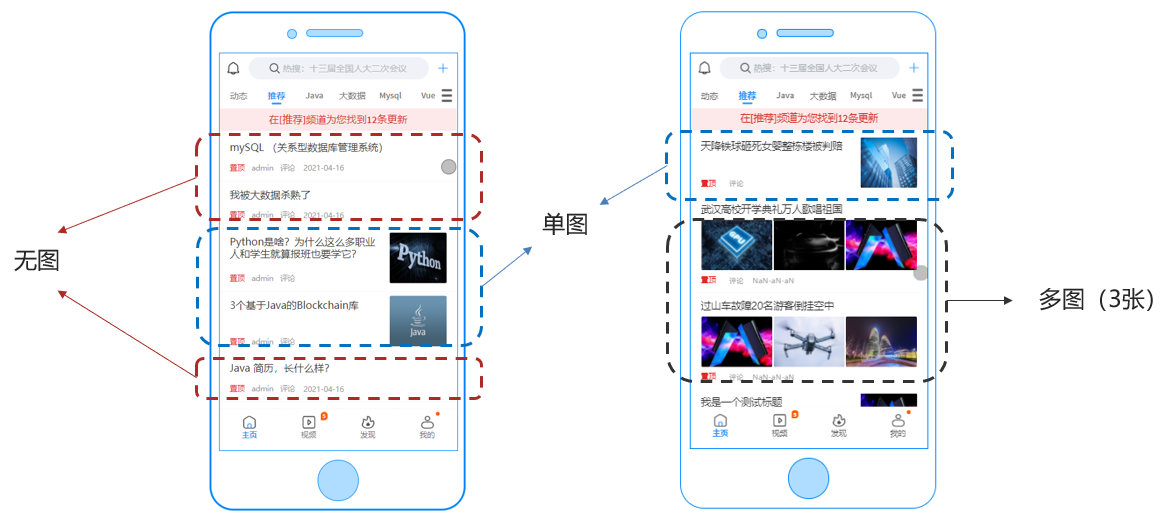

### 1.2 数据表与实体关系

三张表各司其职：

| 表 | 作用 | 关键字段 |
|---|---|---|
| `ap_article` | 文章基本信息 | `id`、标题、作者/频道、布局、封面、统计量、发布时间、`static_url` |
| `ap_article_config` | 发布状态与交互开关 | `article_id`、`is_comment`、`is_forward`、`is_down`、`is_delete` |
| `ap_article_content` | 文章正文 | `article_id`、`content`（文章内容 JSON 字符串） |

实体类用 MyBatis-Plus 的 `@TableName`、`@TableId`、`@TableField` 与表列映射。`author_id`、`channel_id`、`publish_time`、`static_url` 等下划线列需要显式映射或开启驼峰策略。

表结构截图：

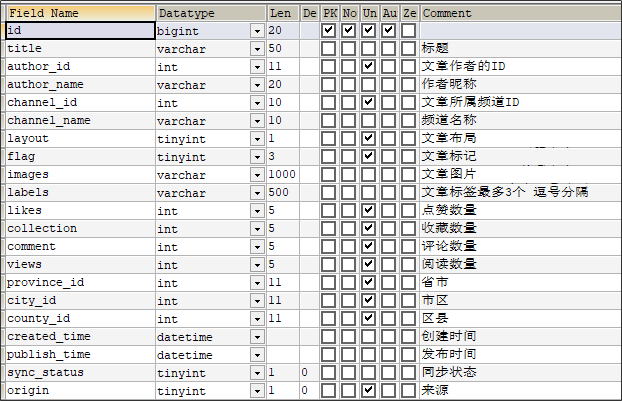

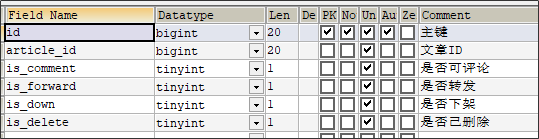

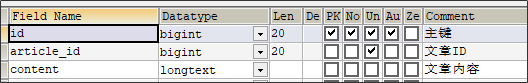

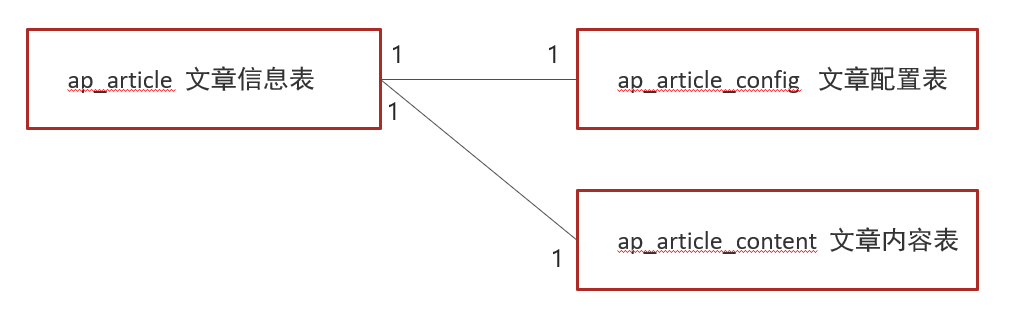

### 1.3 请求对象、接口和网关

```java
@Data
public class ArticleHomeDto {
    private Date maxBehotTime;  // 最新游标
    private Date minBehotTime;  // 最旧游标
    private Integer size;       // 页大小
    private String tag;         // 频道 ID，__all__ 表示全部
}
```

| 场景 | 方法 | 路径 | 负载/响应 |
|---|---|---|---|
| 首页 | POST | `/api/v1/article/load` | `ArticleHomeDto` / `ResponseResult` |
| 加载更多 | POST | `/api/v1/article/loadmore` | 同上 |
| 加载最新 | POST | `/api/v1/article/loadnew` | 同上 |

APP 网关把 `/article/**` 转到 `lb://leadnews-article`，并通过 `StripPrefix=1` 去掉网关前缀。跨域规则要按实际部署收紧；讲义里的全开放配置只适合本地演示。

微服务导入和网关配置的资料截图：

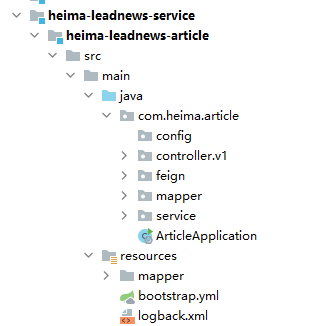

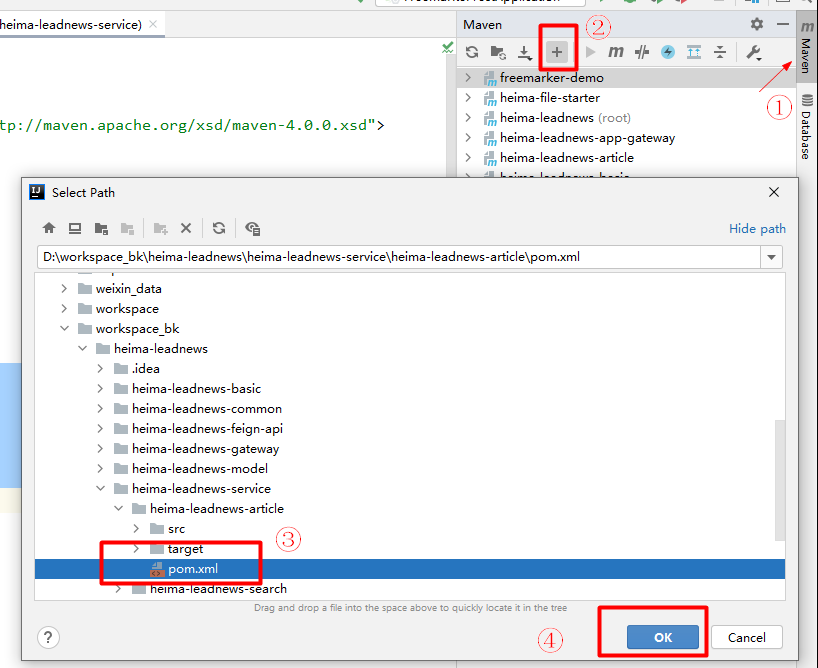

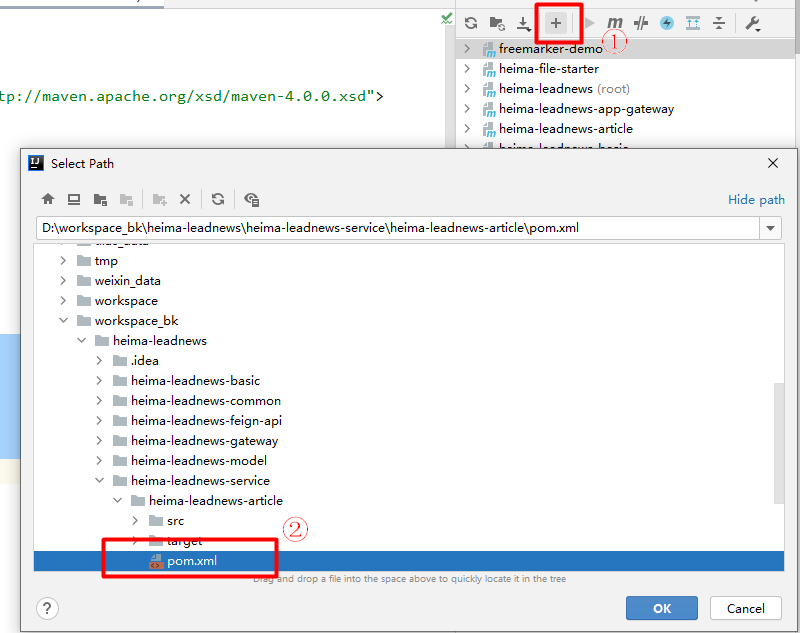

### 1.4 Mapper 查询：把游标变成 SQL 条件

Mapper 方法接收 DTO 和加载类型：

```java
List<ApArticle> loadArticleList(
    @Param("dto") ArticleHomeDto dto,
    @Param("type") Short type);
```

核心 SQL 逻辑（示意）：

```xml
<select id="loadArticleList" resultMap="resultMap">
  SELECT aa.*
  FROM ap_article aa
  LEFT JOIN ap_article_config aac ON aa.id = aac.article_id
  <where>
    aac.is_delete != 1 AND aac.is_down != 1
    <if test="type == 1">
      AND aa.publish_time <![CDATA[<]]> #{dto.minBehotTime}
    </if>
    <if test="type == 2">
      AND aa.publish_time <![CDATA[>]]> #{dto.maxBehotTime}
    </if>
    <if test="dto.tag != '__all__'">
      AND aa.channel_id = #{dto.tag}
    </if>
  </where>
  ORDER BY aa.publish_time DESC
  LIMIT #{dto.size}
</select>
```

`publish_time` 既是排序字段，也是翻页游标；配置表过滤下架和删除数据，频道条件在“全部”标签时跳过。实际项目应考虑空值、重复时间的稳定排序（必要时追加 `id`）。

### 1.5 Service 与 Controller 的职责

Service 负责参数归一化，再查询和封装统一响应：

```java
public ResponseResult load(Short loadtype, ArticleHomeDto dto) {
    int size = dto.getSize() == null || dto.getSize() == 0
            ? 10 : Math.min(dto.getSize(), 50);
    dto.setSize(size);

    if (!LOADTYPE_LOAD_MORE.equals(loadtype)
            && !LOADTYPE_LOAD_NEW.equals(loadtype)) {
        loadtype = LOADTYPE_LOAD_MORE;
    }
    if (StringUtils.isEmpty(dto.getTag())) dto.setTag("__all__");
    if (dto.getMaxBehotTime() == null) dto.setMaxBehotTime(new Date());
    if (dto.getMinBehotTime() == null) dto.setMinBehotTime(new Date());

    return ResponseResult.okResult(
        apArticleMapper.loadArticleList(dto, loadtype));
}
```

Controller 只做路由与类型选择：

```java
@PostMapping("/loadmore")
public ResponseResult loadMore(@RequestBody ArticleHomeDto dto) {
    return service.load(ArticleConstants.LOADTYPE_LOAD_MORE, dto);
}

@PostMapping("/loadnew")
public ResponseResult loadNew(@RequestBody ArticleHomeDto dto) {
    return service.load(ArticleConstants.LOADTYPE_LOAD_NEW, dto);
}
```

建议在真实项目中补充 Bean Validation、统一异常处理、空结果语义和游标边界测试。

## 2. FreeMarker 模板

### 2.1 定位与快速入门

FreeMarker 是嵌入 Java 应用的模板引擎：Java 代码准备数据模型，FTL 模板负责展示，输出可以是 HTML、邮件、配置文件或源代码。常见替代方案包括 JSP、Thymeleaf、Velocity。

FreeMarker 模板与数据模型的关系：

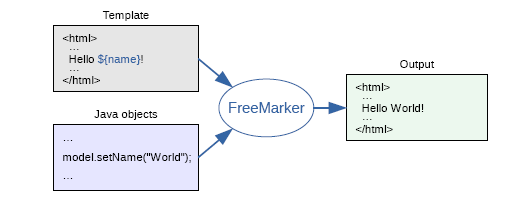

Spring Boot 最小配置（示例端口和目录均为本地占位）：

```yaml
server:
  port: <FREEMARKER_PORT>
spring:
  application:
    name: freemarker-demo
  freemarker:
    cache: false
    suffix: .ftl
    template-loader-path: classpath:/templates
    settings:
      template_update_delay: 0
```

控制器向模型放入普通值和对象：

```java
@GetMapping("/basic")
public String basic(Model model) {
    model.addAttribute("name", "freemarker");
    Student stu = new Student("小明", 18, null, null);
    model.addAttribute("stu", stu);
    return "01-basic";
}
```

模板通过插值表达式取值：

```html
Hello ${name}
姓名：${stu.name}<br>
年龄：${stu.age}
```

页面访问结果示意：

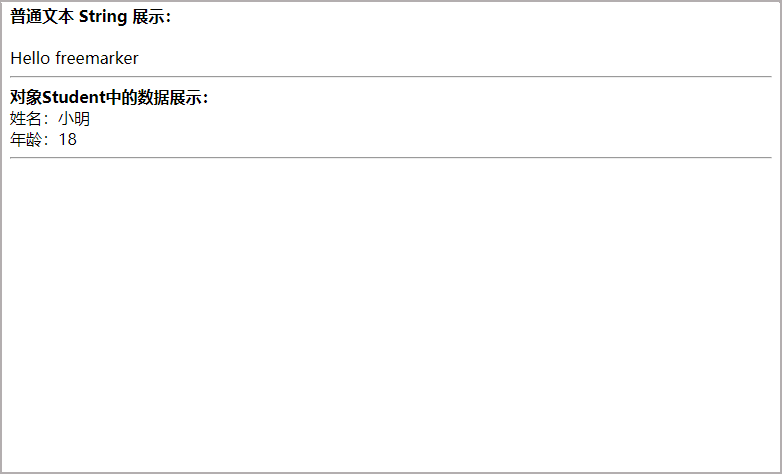

图示来自资料，未在本机启动测试服务。

### 2.2 FTL 语法速记

- 注释：`<#-- ... -->`；普通文本原样输出；插值：`${expression}`。
- List：`<#list stus as stu> ... ${stu_index} ... </#list>`，索引从 0 开始。
- Map：`${stuMap["stu1"].name}` 或 `${stuMap.stu1.name}`；遍历键：`<#list stuMap?keys as key>`。
- 条件：`<#if stu.name == "小红">...<#elseif ...>...<#else>...</#if>`。字符串与数值比较要保持类型一致。
- 算术：`+ - * / %`；比较可用 `== != > >= < <=`，也可用 `gt/gte/lt/lte` 避免 `>` 与 FTL 标签冲突。
- 逻辑：`&&`、`||`、`!`，只能用于布尔表达式。

示例：

```html
<#list stus as stu>
  <#if stu.name == "小红">
    <tr class="highlight"><td>${stu.name}</td></tr>
  <#else>
    <tr><td>${stu.name}</td></tr>
  </#if>
</#list>
```

条件渲染截图：

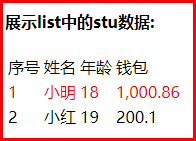

### 2.3 空值与内建函数

在模板边界处理缺失值，避免一个空属性让整页渲染失败：

```ftl
<#if stus??>
  <#list stus as stu>${stu.name!"未知"}</#list>
</#if>
${(stu.bestFriend.name)!""}
```

常用内建函数：

| 表达式 | 用途 |
|---|---|
| `${items?size}` | 集合大小 |
| `${today?date}` / `${today?time}` / `${today?datetime}` | 日期、时间格式化 |
| `${today?string("yyyy-MM")}` | 自定义日期格式 |
| `${point?c}` | 数字按字符串输出，避免本地化千分位 |
| `text?eval` | 将受信任的 JSON 字符串转成模板数据（不要对不可信输入直接执行） |

`!` 只解决缺省值，复杂嵌套通常用括号包裹；日期比较先转成日期类型。

### 2.4 原生 API 静态化

把模板当作 `Template`，把模型和输出流交给 `process`，就能脱离 MVC 视图解析器生成 HTML：

```java
@Autowired
private Configuration configuration;

@Test
public void render() throws Exception {
    Template template = configuration.getTemplate("02-list.ftl");
    Map<String, Object> data = buildDataModel();
    Path target = Paths.get("<OUTPUT_DIR>", "list.html");
    try (Writer writer = Files.newBufferedWriter(target, StandardCharsets.UTF_8)) {
        template.process(data, writer);
    }
}
```

流程：模板文件 → Java 数据模型 → `StringWriter/FileWriter` → HTML 文件。生产代码应明确字符集、关闭流、处理模板异常，并把输出目录交给配置管理。静态化测试示意：

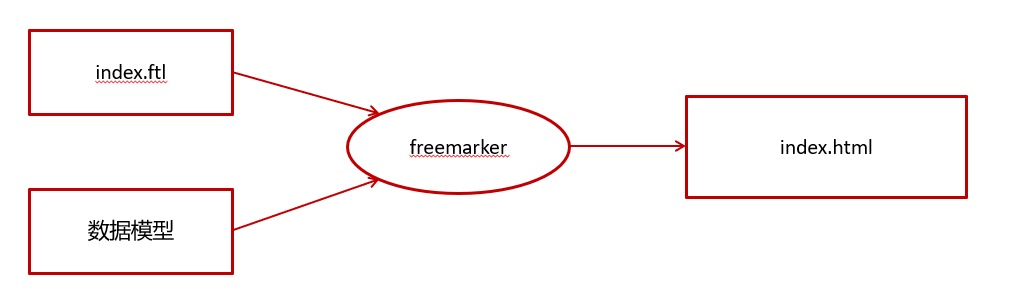

## 3. MinIO 对象存储

### 3.1 概念、特点与本地部署

MinIO 是兼容 S3 接口的轻量对象存储，适合图片、视频、日志、备份和 HTML 等非结构化数据。

- **Bucket**：类似目录；**Object**：文件对象；**Key**：对象名。
- 纠删码提供数据保护；服务端和 SDK 支持多平台；可通过事件通知对接消息或搜索系统。
- 访问策略、分享链接过期和桶权限必须在部署时明确。

讲义使用 Docker 作为示例；本笔记只记录命令形态，不执行：

```bash
docker run -p <MINIO_PORT>:<MINIO_PORT> --name minio -d --restart=always \
  -e "MINIO_ACCESS_KEY=<ACCESS_KEY>" \
  -e "MINIO_SECRET_KEY=<SECRET_KEY>" \
  -v <DATA_DIR>:/data -v <CONFIG_DIR>:/root/.minio \
  minio/minio server /data
```

管理控制台、登录和创建 Bucket 的资料截图：

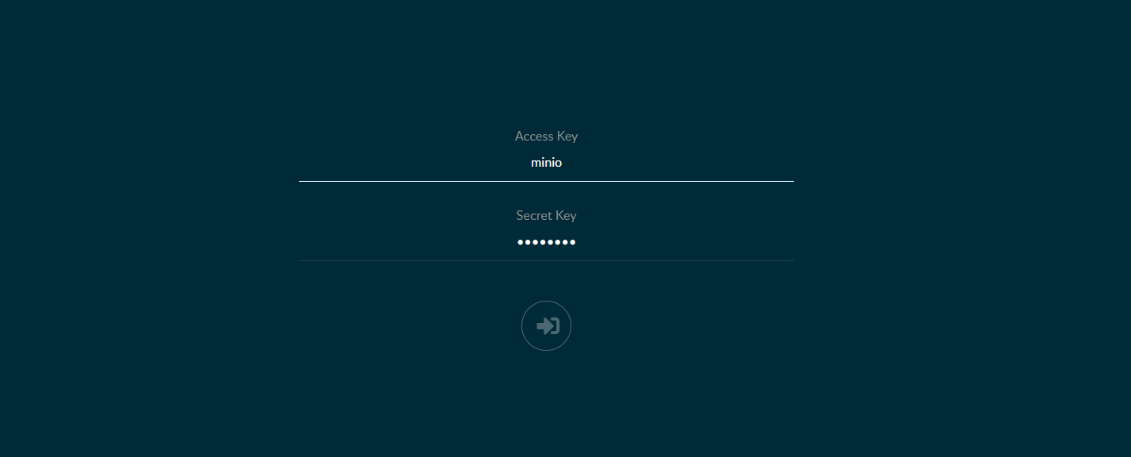

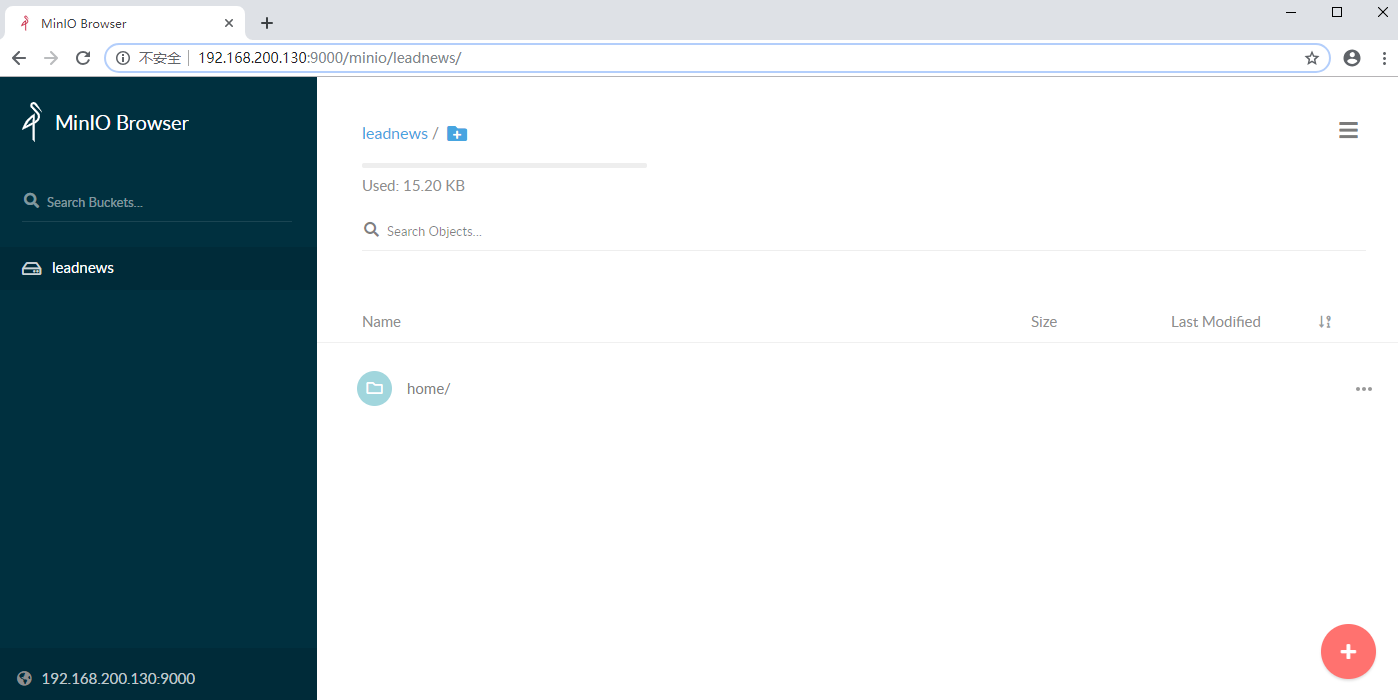

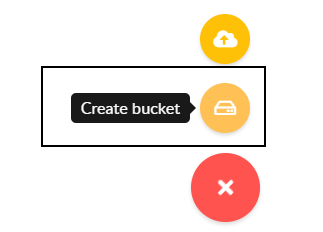

### 3.2 Java SDK 上传

依赖使用 `io.minio:minio`（资料示例为 7.1.0）。上传对象需要客户端、Bucket、Object Key、内容类型和输入流：

```java
MinioClient client = MinioClient.builder()
    .credentials("<ACCESS_KEY>", "<SECRET_KEY>")
    .endpoint("<MINIO_ENDPOINT>")
    .build();

PutObjectArgs args = PutObjectArgs.builder()
    .bucket("<BUCKET>")
    .object("list.html")
    .contentType("text/html")
    .stream(inputStream, inputStream.available(), -1)
    .build();
client.putObject(args);
```

对象 URL 应由服务配置生成，不能把示例 IP、账号或密钥硬编码进业务代码。上传图片时使用正确的 MIME 类型；大文件要考虑流长度、分片和异常重试。

### 3.3 封装成 Spring Boot Starter

starter 的目标是让业务服务只注入 `FileStorageService`，而不依赖 MinIO SDK 细节。模块结构：

```text
heima-file-starter
├─ MinIOConfigProperties   # minio.* 配置
├─ MinIOConfig             # 条件装配 MinioClient
├─ FileStorageService      # 上传/删除/下载抽象
├─ MinIOFileStorageService # 默认实现
└─ META-INF/spring.factories
```

配置属性：

```java
@ConfigurationProperties(prefix = "minio")
public class MinIOConfigProperties {
    private String accessKey;
    private String secretKey;
    private String bucket;
    private String endpoint;
    private String readPath;
}
```

配置示例用占位符保护凭据：

```yaml
minio:
  accessKey: <ACCESS_KEY>
  secretKey: <SECRET_KEY>
  bucket: <BUCKET>
  endpoint: <MINIO_ENDPOINT>
  readPath: <MINIO_READ_PATH>
```

`@EnableConfigurationProperties` 注册配置，`@ConditionalOnClass(FileStorageService.class)` 控制自动装配，`spring.factories` 暴露 `MinIOFileStorageService`。业务服务导入 starter 后即可 `@Autowired FileStorageService`。

### 3.4 文件服务接口与路径策略

```java
public interface FileStorageService {
    String uploadImgFile(String prefix, String filename, InputStream input);
    String uploadHtmlFile(String prefix, String filename, InputStream input);
    void delete(String pathUrl);
    byte[] downLoadFile(String pathUrl);
}
```

实现类把对象 Key 统一构造成：`<prefix>/yyyy/MM/dd/<filename>`，再拼接 `readPath/bucket/key` 作为可读地址。删除和下载时要从 URL 中可靠解析 Bucket 与 Key，校验路径归属，避免字符串替换导致越权；输入流读取失败时要返回明确异常并关闭资源。

工程资料中的 starter 配置和封装步骤截图：

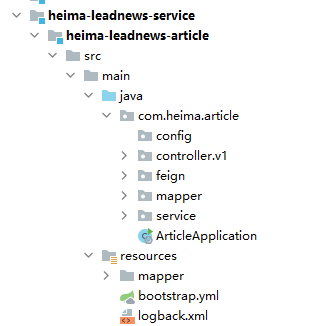

这里引用的截图来自同一批资料，用来对应模块接入流程；实际工程以源码中的包名和版本为准。

## 4. 文章详情静态页

### 4.1 两种方案

**方案一：实时渲染**

用户点击文章后按 ID 查询 `ap_article_content`，把正文交给模板渲染并返回页面。实现简单，但每次访问都占用数据库和渲染资源。

**方案二：发布时静态化**

文章发布或变更时生成 `article.html`，上传 MinIO，把 URL 保存到 `ap_article.static_url`；APP 后续直接访问静态 URL。读链路短、缓存友好，代价是需要处理发布失败、更新和清理旧对象。

方案示意：

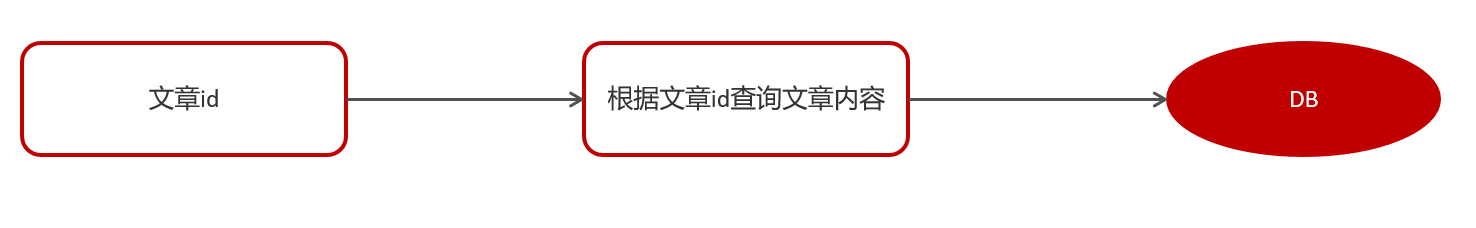

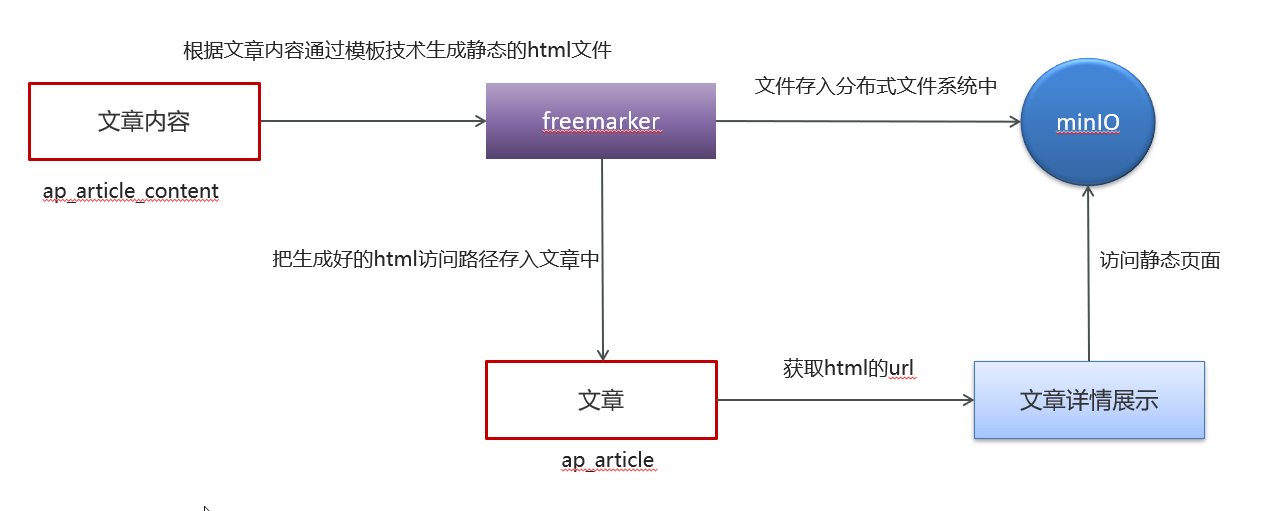

需求界面：

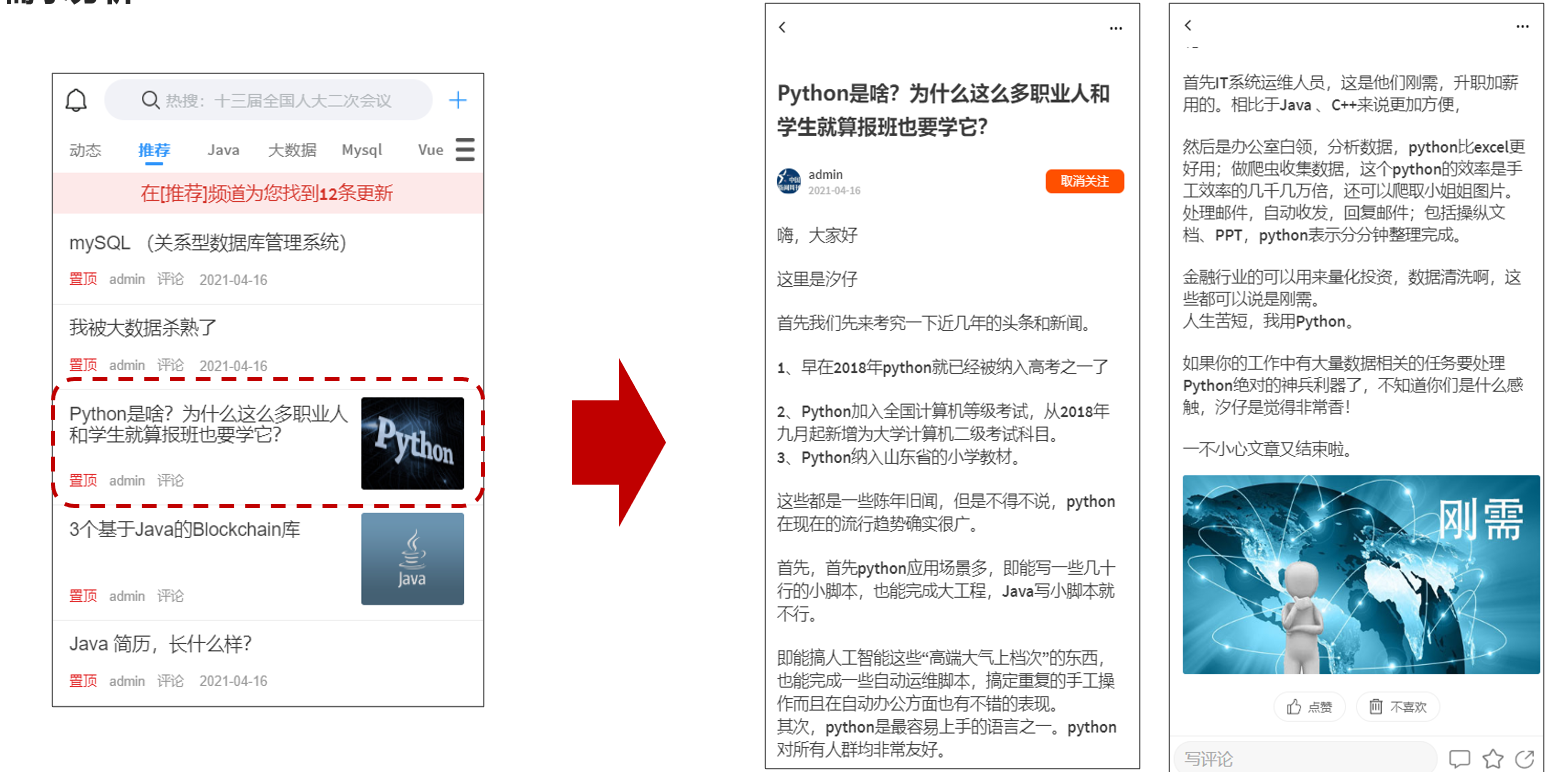

### 4.2 生成静态详情的实现步骤

1. 在 article 微服务引入 `spring-boot-starter-freemarker` 和 `heima-file-starter`。
2. 把 `article.ftl` 放到 `resources/templates`；把模板依赖的 `index.js`、`index.css` 作为对象上传 MinIO。
3. 新增 `ApArticleContentMapper`，按 `article_id` 读取正文。
4. 组装模板数据：讲义中的正文是 JSON 数组，先解析为可遍历结构，再 `template.process` 到 `StringWriter`。
5. 用 `uploadHtmlFile` 上传 `<articleId>.html`，拿到 URL。
6. 更新 `ap_article.static_url`；生产实现应在事务、幂等、重试和旧文件清理之间做清晰边界。

核心代码（去掉真实 ID、地址和凭据）：

```java
ApArticleContent content = contentMapper.selectOne(
    Wrappers.<ApArticleContent>lambdaQuery()
        .eq(ApArticleContent::getArticleId, articleId));

if (content != null && StringUtils.isNotBlank(content.getContent())) {
    Template template = configuration.getTemplate("article.ftl");
    Map<String, Object> data = new HashMap<>();
    data.put("content", JSONArray.parseArray(content.getContent()));

    StringWriter out = new StringWriter();
    template.process(data, out);
    try (InputStream in = new ByteArrayInputStream(
            out.toString().getBytes(StandardCharsets.UTF_8))) {
        String staticUrl = fileStorageService.uploadHtmlFile(
            "", articleId + ".html", in);
        articleMapper.updateById(
            new ApArticle().setId(articleId).setStaticUrl(staticUrl));
    }
}
```

模板放置与静态资源上传截图：

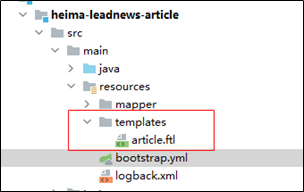

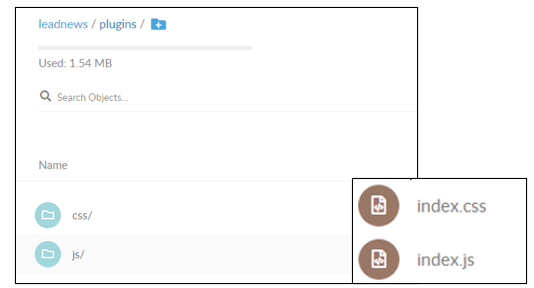

## 5. 易错点、验证清单与复习

### 常见坑

- `loadmore` 与 `loadnew` 的时间条件方向相反，必须配合倒序排序和正确游标。
- `size`、`tag`、时间为空时要在 Service 兜底，不能把默认值责任全交给前端。
- MyBatis XML 中 `<`、`>` 需要 CDATA 或转义；字段映射要覆盖下划线列。
- FreeMarker 缺失变量会中断渲染，使用 `??` 和 `!` 做边界保护；`?eval` 只处理可信内容。
- MinIO 的 Bucket、Object Key、访问 URL 是三个概念；删除/下载不能只靠脆弱的字符串截取。
- 静态化生成成功不代表用户能访问，还要检查对象权限、MIME 类型、静态资源 URL 和 CDN/网关策略。
- 资料中的固定 IP、端口、账号、密码和本地路径均为演示值，部署时从安全配置注入。

### 自测任务

1. 画出 `loadnew` 从 APP 到 MySQL 的请求链路，说明两个时间游标的作用。
2. 为文章列表查询增加稳定的二级排序和重复时间处理。
3. 用一个 List 和 Map 模型写出 FreeMarker 列表页，并补齐空值保护。
4. 说明为什么文章详情适合“发布时静态化”，以及失败重试如何设计。
5. 给 `FileStorageService` 增加 `contentType` 参数并设计异常/资源关闭策略。

本篇完成后，下一阶段可以继续接入文章发布流程，让“发布文章 → 生成静态页 → 上传 MinIO → 回写 URL”自动化。